# Lab 6: Logistic Regression & KNN Classification

**Name:** Shabab Zahra 

**CMS ID:** 023-24-0088

**Section:** D

**GitHub:** https://github.com/shababzahraa/Machine-Learning-Tasks 

### Part 1 — Problem Definition & Dataset Verification

In [1]:
#1.	Load clean_churn.csv (or re-run your Lab 2 cleaning) and verify its shape and dtypes.
import pandas as pd 
df = pd.read_csv("Clean_churn.csv")
print("Shape:",df.shape)
print(df.dtypes)

Shape: (7043, 20)
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


2.	Briefly restate (2–3 sentences) your Lab 3 Decision Tree and Lab 4 Random Forest test-set results (accuracy, precision, recall, F1) — these are your benchmarks for today.

In Lab 3, the Decision Tree achieved a test accuracy of 79.56%, with a precision of 64.43%, recall of 51.34%, and F1-score of 57.14%. In Lab 4, the Random Forest achieved a test accuracy of 78.78%, with a precision of 62.80%, recall of 49.20%, and F1-score of 55.17%. These results will be used as benchmarks for comparing Logistic Regression and KNN in this lab.

### Part 2 — Feature Scaling & Preparation

In [2]:
#3.	Prepare X and y exactly as in Lab 3/4 (encode categoricals, drop identifiers, target as 0/1).
y = df['Churn'].map({'Yes': 1, 'No' : 0})
X = df.drop(columns=['Churn'])
x = pd.get_dummies(X, drop_first=True)
print("X Shape:",x.shape)
print("Y Shape:",y.shape)

X Shape: (7043, 30)
Y Shape: (7043,)


4.	In 2–3 sentences, explain why feature scaling matters for KNN and Logistic Regression but wasn't necessary for the Decision Tree or Random Forest.

Feature scaling is important for KNN because KNN uses distance between data points, so features with larger numerical values can dominate the distance calculation. It also helps Logistic Regression by putting features on a similar scale, making the model's coefficients more comparable and optimization more stable. Decision Trees and Random Forests do not require scaling because they make decisions using feature thresholds rather than calculating distances.

In [3]:
#5.	Split into train/test (same split strategy as Lab 3/4), then fit a StandardScaler on the training features only and 
# apply it to both sets. Why is it important to fit the scaler only on the training data?
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=42, test_size=0.2, stratify=y)

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)

x_test_scaled = scaler.transform(x_test)

print("Training set:", x_train_scaled.shape)
print("Test set:", x_test_scaled.shape)



Training set: (5634, 30)
Test set: (1409, 30)


The scaler is fitted only on the training data to prevent data leakage. If the test data were used to fit the scaler, information from the unseen test set would influence the preprocessing and could make the model evaluation unfair. Therefore, the training data is used to fit the scaler, and the same scaling parameters are applied to both training and test data.

### Part 3 — Logistic Regression

In [4]:
#6.	Train a LogisticRegression model on the scaled training data. Generate predictions on the scaled test set.
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(random_state=42)

lr_model.fit(x_train_scaled, y_train)

y_pred = lr_model.predict(x_test_scaled)

print("Predictions")
print(y_pred[:10])


Predictions
[0 1 0 0 0 1 0 0 0 0]


Accuracy:  0.807
Precision:  0.6584
Recall:  0.5668
F1 Score:  0.6092


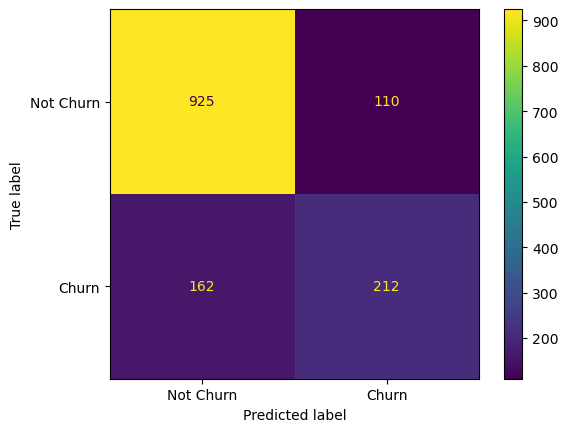

In [5]:
#7.	Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy: ", round(accuracy,4))
print("Precision: ", round(precision,4))
print("Recall: ", round(recall,4))
print("F1 Score: ", round(f1,4))

confusion = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion, display_labels=['Not Churn', 'Churn']).plot()

In [6]:
#8.	Look at predict_proba for a handful of test customers. 
# In 1–2 sentences, explain what these probabilities represent and how predict() turns them into a Yes/No decision.
probabilties = lr_model.predict_proba(x_test_scaled)
print(probabilties[:10])

[[0.95542292 0.04457708]
 [0.31559833 0.68440167]
 [0.94340109 0.05659891]
 [0.59271149 0.40728851]
 [0.97841844 0.02158156]
 [0.39550021 0.60449979]
 [0.54753653 0.45246347]
 [0.86894417 0.13105583]
 [0.99715797 0.00284203]
 [0.60608153 0.39391847]]


predict_proba() gives the probability of each class for a customer: No Churn (0) and Churn (1). predict() chooses the class with the higher probability (using the default 0.5 threshold), giving the final Yes/No churn prediction.

### Part 4 — KNN & Choosing K

In [7]:
#9.	Train KNN classifiers for several values of K (e.g. 1, 3, 5, 7, 9, 11, 15, 21) on the scaled data. 
# Record test-set accuracy and F1-score for each K in a results table.
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
knn_acc = []
for k in k_values:
    knn_model = KNeighborsClassifier(n_neighbors=k)
    
    knn_model.fit(x_train_scaled, y_train)

    knn_pred=knn_model.predict(x_test_scaled)

    k_accuracy = round(accuracy_score(y_test, knn_pred),4)
    k_f1 = f1_score(y_test, knn_pred)

    knn_acc.append(k_accuracy)
    print("k = ", k,"Accuracy = ", k_accuracy,4, "F1 score = ", round(k_f1,4))


k =  1 Accuracy =  0.7161 4 F1 score =  0.4764
k =  3 Accuracy =  0.7438 4 F1 score =  0.5128
k =  5 Accuracy =  0.7473 4 F1 score =  0.5123
k =  7 Accuracy =  0.7594 4 F1 score =  0.5324
k =  9 Accuracy =  0.77 4 F1 score =  0.5586
k =  11 Accuracy =  0.7729 4 F1 score =  0.5616
k =  15 Accuracy =  0.7693 4 F1 score =  0.553
k =  21 Accuracy =  0.7708 4 F1 score =  0.5617


### KNN Results

| K | Accuracy | F1 Score |
|---:|---:|---:|
| 1  | 0.7161 | 0.4764 |
| 3  | 0.7438 | 0.5128 |
| 5  | 0.7473 | 0.5123 |
| 7  | 0.7594 | 0.5324 |
| 9  | 0.7700 | 0.5586 |
| 11 | 0.7729 | 0.5616 |
| 15 | 0.7693 | 0.5530 |
| 21 | 0.7708 | 0.5617 |

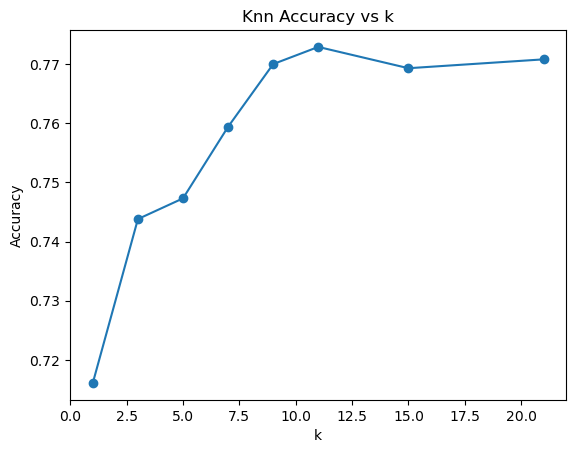

In [8]:
#10.	Plot accuracy (or F1) against K. Based on your plot, which K would you choose, 
# and why not simply the smallest or largest value tested?
import matplotlib.pyplot as plt
plt.plot(k_values,knn_acc, marker='o')
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Knn Accuracy vs k")
plt.show()

Based on the plot, I would choose **K = 11** because it gives the highest test accuracy of **0.7729** among the tested values. I would not choose the smallest K because it can be more sensitive to individual data points, while a very large K can make the model too smooth and less sensitive to local patterns.

Accuracy : 0.7729
Precision: 0.5758
Recall   : 0.5481
F1 Score : 0.5616


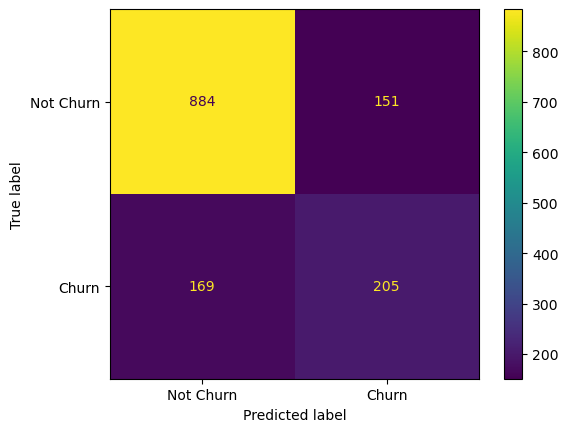

In [9]:
#11.	Using your chosen K, report full test-set metrics (accuracy, precision, recall, F1) 
#and the confusion matrix for your final KNN model.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
k_final_model = KNeighborsClassifier(n_neighbors=11)

k_final_model.fit(x_train_scaled, y_train)

k_final_pred = k_final_model.predict(x_test_scaled)

k_final_accuracy = round(accuracy_score(y_test, k_final_pred),4)
k_final_precision = round(precision_score(y_test, k_final_pred),4)
k_final_recall = round(recall_score(y_test, k_final_pred),4)
k_final_f1 = round(f1_score(y_test, k_final_pred),4)

print("Accuracy :", k_final_accuracy)
print("Precision:", k_final_precision)
print("Recall   :", k_final_recall)
print("F1 Score :", k_final_f1)

k_final_confusion = confusion_matrix(y_test, k_final_pred)
ConfusionMatrixDisplay(k_final_confusion, display_labels=['Not Churn', 'Churn']).plot()



### Part 5 — Model Comparison (4 Models)

12.	Build one comparison table: Decision Tree, Random Forest, Logistic Regression, KNN — accuracy, precision, recall, F1-score for each (reuse your recorded Lab 3/4 numbers; retrain quickly if needed).

| Model | Accuracy | Precision | Recall | F1 Score |
|---|---:|---:|---:|---:|
| Decision Tree | 0.7956 | 0.6443 | 0.5134 | 0.5714 |
| Tuned Random Forest | 0.8006 | 0.6566 | 0.5214 | 0.5812 |
| Logistic Regression | 0.8070 | 0.6584 | 0.5668 | 0.6092 |
| KNN (K=11) | 0.7729 | 0.5758 | 0.5481 | 0.5616 |

13.	Which model performs best overall? Does the ranking change depending on which metric you prioritize (e.g. precision vs. recall)? Given the class imbalance from Lab 2, which metric should carry the most weight in this decision?

Based on the results, **Logistic Regression** performs best overall because it has the highest accuracy (0.8070), precision (0.6584), recall (0.5668), and F1-score (0.6092) among the four models. The ranking does not change when comparing precision, recall, or F1-score because Logistic Regression has the highest value for each metric.

Because the dataset has class imbalance and the goal is to identify customers who are likely to churn, **recall should carry the most weight**. Higher recall means the model can identify more of the actual churners and reduce the number of churners that are incorrectly classified as non-churners.

### Part 6 — Coefficient Interpretation

In [11]:
#14.	Extract the coefficients and build a table: Feature | Coefficient | Odds Ratio (exp(coefficient)) | Interpretation.
# Interpret at least 4 features (e.g. "customers on this contract type have roughly ___× the odds of churning, holding other features constant").
import numpy as np
import pandas as pd

coefficients = lr_model.coef_[0]

odds_ratios = np.exp(coefficients)

coef_table = pd.DataFrame({
    'Feature': x_train.columns,
    'Coefficient': coefficients,
    'Odds Ratio': odds_ratios
})
coef_table

,Feature,Coefficient,Odds Ratio
0,SeniorCitizen,0.053468,1.054923
1,tenure,-1.232969,0.291426
2,MonthlyCharges,-0.932598,0.393530
3,TotalCharges,0.507261,1.660736
4,gender_Male,0.011303,1.011367
5,Partner_Yes,0.010538,1.010593
6,Dependents_Yes,-0.103744,0.901456
7,PhoneService_Yes,0.008498,1.008534
8,MultipleLines_No phone service,-0.008498,0.991538
9,MultipleLines_Yes,0.218169,1.243798


15.	Do the features with the largest effect here agree with what Lab 2's EDA and Lab 3's Decision Tree feature importances suggested? Note any disagreements.

Yes, the features with the largest effects in the Logistic Regression model largely agree with the findings from Lab 2 EDA and Lab 3 Decision Tree. Tenure, MonthlyCharges, and InternetService were identified as important features in the earlier labs, and they also have relatively large effects in the Logistic Regression model. In particular, the Fiber optic category of InternetService has a relatively large positive coefficient (0.782). TotalCharges also has a noticeable effect in the Logistic Regression model, although it was less prominent in the earlier feature-importance results. Overall, the main findings are consistent, with some differences in the exact ranking of features because Logistic Regression and Decision Trees measure feature effects differently.

16.	Select your final model from all four candidates and justify the choice in 2–3 sentences, referencing your Part 5 comparison table and Lab 4's cross-validation lesson about not trusting a single number too much.

I select Logistic Regression as the final model because it has the highest accuracy (0.8070), recall (0.5668), and F1-score (0.6092) among the four models, while also having competitive precision (0.6584). However, following Lab 4's cross-validation lesson, I would not rely on a single test-set metric; the model's consistent performance across multiple metrics makes Logistic Regression the most suitable final choice.

17.	Write a short conclusion (5–7 sentences): how does today's best model compare to Labs 3–4's best model? What did feature scaling change? What are the remaining limitations of your best model, and what would you try next?

Today's best model is Logistic Regression, with an accuracy of 80.70% and an F1-score of 60.92%, slightly outperforming the tuned Random Forest from Labs 3–4. Feature scaling was important for models such as Logistic Regression and KNN because it puts numerical features on a similar scale, preventing large-valued features from dominating the model. Scaling does not have the same effect on tree-based models such as Decision Trees and Random Forests. The Logistic Regression model still has limitations, including the class imbalance and its assumption of a mostly linear relationship between the features and the log-odds of churn. Its recall of 56.68% also means that some customers who actually churn are still missed. As a next step, I would try further hyperparameter tuning, class-weighting or other imbalance-handling techniques, and cross-validation to check whether the performance generalizes to unseen data.